# Sinhala textbook dataset — analysis

Corpus: `textbooks/markdown/<subject>/grade_<N>[_part_<K>].md` — Sri Lankan Sinhala-medium textbooks,
grades 6–11, extracted by `extract_arts.py` / `extract_technical.py` (see `textbooks/markdown/README.md`).

This notebook measures what is in the corpus before preprocessing for fine-tuning:
size (characters, words, **SinLlama tokens**), structure (block types), script mix, extraction
noise, duplication, exercise/activity content and vocabulary. It ends with the preprocessing
decisions the numbers point to.

In [1]:
import re, json, random, unicodedata
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

ROOT = Path('..') if Path.cwd().name == 'textbooks' else Path('.')
DATA = ROOT / 'textbooks' / 'markdown'
TOKENIZER = ROOT / 'models' / 'SinLlama_cpt'   # same tokenizer as Wikipedia_Dataset/tokenizer

ARTS = set(k.split('/')[0] for k in json.loads((DATA / '_report.json').read_text()))

# reference palette, light mode: slot 1 (blue) arts, slot 2 (orange) technical
KIND_COLOR = {'arts': '#2a78d6', 'technical': '#eb6834'}
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': GRID,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})
pd.set_option('display.max_colwidth', 120)
print(DATA.resolve())

/ml/SinLlama_CPT/textbooks/markdown


## 1. Load the books

In [2]:
tok = AutoTokenizer.from_pretrained(TOKENIZER)

rows = []
for f in sorted(DATA.glob('*/*.md')):
    if f.name == 'README.md':
        continue
    m = re.match(r'grade_(\d+)(?:_part_(\d+))?', f.stem)
    text = f.read_text(encoding='utf-8')
    rows.append({'subject': f.parent.name, 'grade': int(m[1]), 'part': int(m[2] or 1),
                 'kind': 'arts' if f.parent.name in ARTS else 'technical',
                 'path': str(f.relative_to(DATA)), 'text': text})
books = pd.DataFrame(rows)
books['chars'] = books.text.str.len()
books['words'] = books.text.str.split().str.len()
books['tokens'] = [len(tok(t, add_special_tokens=False).input_ids) for t in books.text]
books['tok_per_word'] = books.tokens / books.words
print(len(books), 'books')
books.drop(columns='text').head()

113 books


,subject,grade,part,kind,path,chars,words,tokens,tok_per_word
0,agriculture_food_tech,10,1,technical,agriculture_food_tech/grade_10.md,247925,44105,70749,1.604104
1,agriculture_food_tech,11,1,technical,agriculture_food_tech/grade_11.md,250225,43480,66540,1.530359
2,aquatic_bioresources_tech,10,1,technical,aquatic_bioresources_tech/grade_10.md,170405,29539,48106,1.628559
3,aquatic_bioresources_tech,11,1,technical,aquatic_bioresources_tech/grade_11.md,177262,30209,46702,1.545963
4,buddhism,10,1,arts,buddhism/grade_10.md,214660,35881,55503,1.546863


## 2. Size

In [3]:
tot = books.groupby('kind')[['chars', 'words', 'tokens']].sum()
tot.loc['total'] = tot.sum()
print(f"books: {len(books)}  |  tokens: {books.tokens.sum():,}  |  tokens/word (SinLlama): {books.tokens.sum() / books.words.sum():.2f}")
tot.style.format('{:,}')

books: 113  |  tokens: 5,410,378  |  tokens/word (SinLlama): 1.66


,chars,words,tokens
kind,,,
arts,"9,982,519","1,654,650","2,581,182"
technical,"8,946,576","1,610,663","2,829,196"
total,"18,929,095","3,265,313","5,410,378"


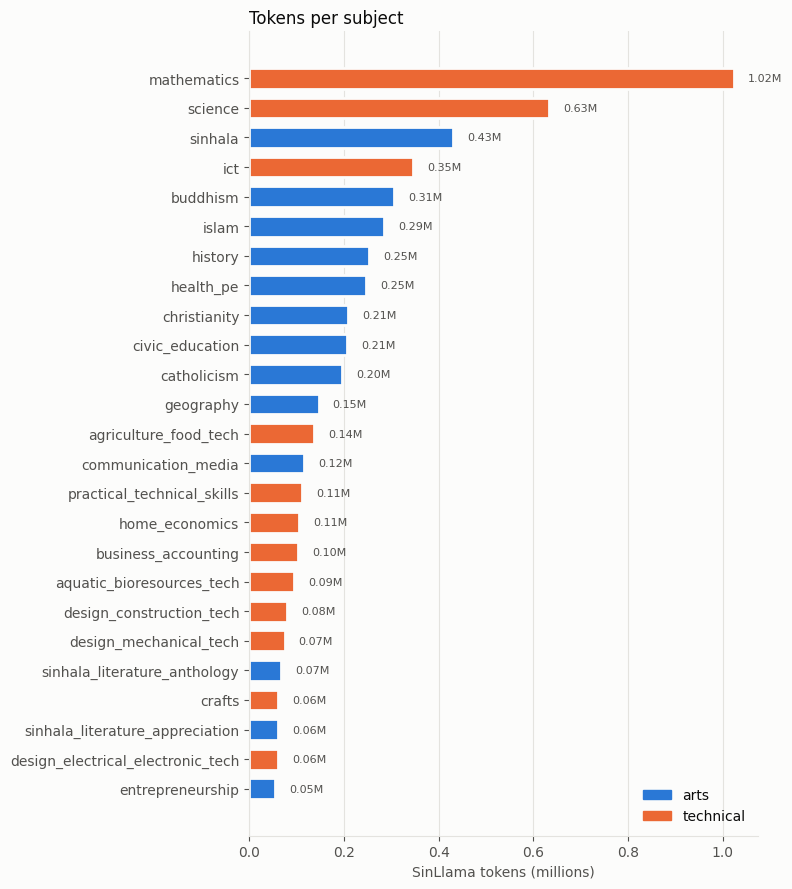

,subject,kind,books,tokens,words,grades
19,mathematics,technical,14,"1,022,530","543,399",6–11
21,science,technical,11,"632,597","362,132",6–11
22,sinhala,arts,6,"429,353","262,463",6–11
17,ict,technical,10,"345,256","181,364",6–11
2,buddhism,arts,6,"306,781","197,293",6–11
18,islam,arts,6,"285,290","171,252",6–11
15,history,arts,6,"253,413","168,993",6–11
14,health_pe,arts,5,"247,774","166,678",6–11
5,christianity,arts,6,"208,970","136,085",6–11
6,civic_education,arts,6,"207,173","146,695",6–11


In [4]:
by_subj = (books.groupby(['subject', 'kind'])
           .agg(books=('path', 'size'), tokens=('tokens', 'sum'), words=('words', 'sum'),
                grades=('grade', lambda g: f'{g.min()}–{g.max()}'))
           .reset_index().sort_values('tokens'))

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(by_subj.subject, by_subj.tokens / 1e6, color=[KIND_COLOR[k] for k in by_subj.kind],
        height=0.7, edgecolor='#fcfcfb', linewidth=2)
for y, v in enumerate(by_subj.tokens / 1e6):
    ax.text(v + 0.03, y, f'{v:.2f}M', va='center', fontsize=8, color=INK2)
ax.set_xlabel('SinLlama tokens (millions)')
ax.set_title('Tokens per subject', loc='left', fontsize=12)
ax.grid(axis='y', visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in KIND_COLOR.values()],
          labels=list(KIND_COLOR), frameon=False, loc='lower right')
plt.tight_layout(); plt.show()
by_subj.sort_values('tokens', ascending=False).style.format({'tokens': '{:,}', 'words': '{:,}'})

In [5]:
grid = books.pivot_table(index='subject', columns='grade', values='tokens', aggfunc='sum')
(grid / 1000).round(0).fillna('').astype(str).replace('', '·')  # thousands of tokens; · = no book

grade,6,7,8,9,10,11
subject,,,,,,
agriculture_food_tech,·,·,·,·,71.0,67.0
aquatic_bioresources_tech,·,·,·,·,48.0,47.0
buddhism,30.0,47.0,55.0,60.0,56.0,59.0
business_accounting,·,·,·,·,61.0,42.0
catholicism,31.0,28.0,29.0,31.0,42.0,36.0
christianity,28.0,22.0,38.0,28.0,52.0,40.0
civic_education,24.0,24.0,37.0,48.0,31.0,44.0
communication_media,·,·,·,·,69.0,47.0
crafts,·,·,·,·,·,62.0


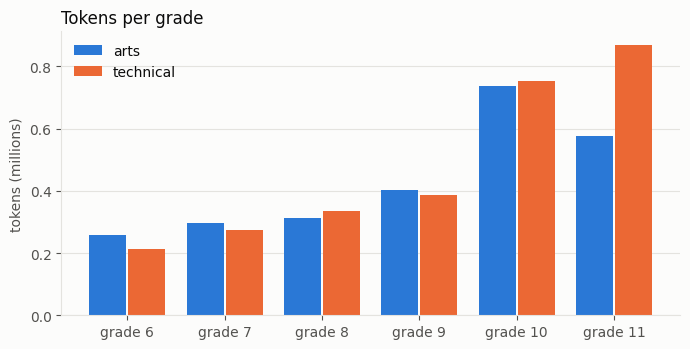

In [6]:
g = books.groupby(['grade', 'kind']).tokens.sum().unstack(fill_value=0) / 1e6
fig, ax = plt.subplots(figsize=(7, 3.6))
x = range(len(g))
ax.bar([i - 0.2 for i in x], g['arts'], width=0.38, color=KIND_COLOR['arts'], label='arts')
ax.bar([i + 0.2 for i in x], g['technical'], width=0.38, color=KIND_COLOR['technical'], label='technical')
ax.set_xticks(list(x), [f'grade {i}' for i in g.index]); ax.grid(axis='x', visible=False)
ax.set_ylabel('tokens (millions)'); ax.set_title('Tokens per grade', loc='left', fontsize=12)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 3. Structure — block types

A *block* is a paragraph-level unit (separated by a blank line): heading, paragraph, list item,
table, verse, display equation, caption, figure placeholder.

In [7]:
def block_type(b):
    if b.startswith('# '): return 'title'
    if b.startswith('#'): return 'heading'
    if b.startswith('|'): return 'table'
    if b.startswith('$$') or b.startswith('\\['): return 'display_math'
    if b.startswith('*') and b.endswith('*') and not b.startswith('* '): return 'caption'
    if b.startswith('[රූපය'): return 'figure'
    if re.match(r'^(\d+|[a-zA-Z]|[ivx]+)[.)] |^\((\d+|[ivx]+)\) |^[-*•] ', b): return 'list_item'
    if '\n' in b: return 'verse/multiline'
    return 'paragraph'

blocks = pd.DataFrame([{'path': r.path, 'subject': r.subject, 'kind': r.kind, 'grade': r.grade, 'block': b}
                       for r in books.itertuples() for b in r.text.split('\n\n') if b.strip()])
blocks['type'] = blocks.block.map(block_type)
blocks['chars'] = blocks.block.str.len()
blocks['words'] = blocks.block.str.split().str.len()
print(f'{len(blocks):,} blocks')
share = (blocks.groupby(['kind', 'type']).chars.sum() / blocks.groupby('kind').chars.sum()).unstack(0)
(share * 100).round(1).sort_values('arts', ascending=False).style.format('{:.1f}%')

180,550 blocks


kind,arts,technical
type,,
paragraph,71.5%,50.5%
list_item,15.2%,22.5%
heading,4.9%,4.8%
verse/multiline,4.7%,7.6%
table,2.4%,10.8%
caption,1.1%,2.0%
title,0.2%,0.1%
display_math,nan%,1.4%
figure,nan%,0.3%


In [8]:
typ = (blocks.groupby(['subject', 'type']).chars.sum()
       / blocks.groupby('subject').chars.sum()).unstack(fill_value=0) * 100
typ[['paragraph', 'heading', 'list_item', 'table', 'verse/multiline', 'display_math', 'caption', 'figure']].round(1)

type,paragraph,heading,list_item,table,verse/multiline,display_math,caption,figure
subject,,,,,,,,
agriculture_food_tech,47.3,5.2,32.4,8.5,4.9,0.0,1.7,0.0
aquatic_bioresources_tech,57.6,6.2,20.7,7.1,5.7,0.0,2.7,0.0
buddhism,85.5,2.4,9.1,1.0,1.7,0.0,0.0,0.0
business_accounting,55.4,5.9,7.0,21.6,9.7,0.0,0.4,0.0
catholicism,66.7,4.8,18.6,2.8,5.4,0.0,1.4,0.0
christianity,76.2,9.5,8.2,1.4,3.9,0.0,0.2,0.0
civic_education,63.4,8.1,19.3,4.0,4.5,0.0,0.8,0.0
communication_media,72.8,5.1,16.1,0.9,4.3,0.0,0.9,0.0
crafts,66.8,4.8,21.6,3.7,2.3,0.0,0.7,0.0


### Paragraph length (tokens) — matters for chunking into training sequences

count    66505.0
mean        44.8
std         58.0
min          1.0
50%         29.0
90%        100.0
99%        232.0
max       4004.0


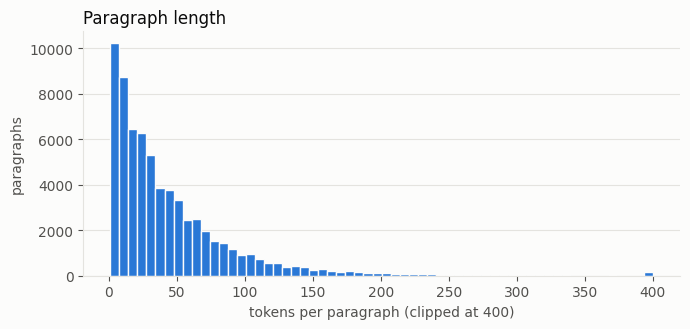

In [9]:
para = blocks[blocks.type == 'paragraph'].copy()
para['tokens'] = [len(tok(b, add_special_tokens=False).input_ids) for b in para.block]
print(para.tokens.describe(percentiles=[.5, .9, .99]).round(1).to_string())

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(para.tokens.clip(upper=400), bins=60, color=KIND_COLOR['arts'], edgecolor='#fcfcfb', linewidth=1)
ax.set_xlabel('tokens per paragraph (clipped at 400)'); ax.set_ylabel('paragraphs')
ax.set_title('Paragraph length', loc='left', fontsize=12); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

In [10]:
chapters = []   # text between '# ' titles = chapter-sized units
for r in books.itertuples():
    for ch in re.split(r'\n(?=# )', r.text):
        chapters.append({'path': r.path, 'kind': r.kind,
                         'tokens': len(tok(ch, add_special_tokens=False).input_ids)})
chapters = pd.DataFrame(chapters)
print(f'{len(chapters):,} chapter-sized units')
chapters.groupby('kind').tokens.describe(percentiles=[.5, .9]).round(0)

1,451 chapter-sized units


,count,mean,std,min,50%,90%,max
kind,,,,,,,
arts,966.0,2672.0,3611.0,3.0,1850.0,4840.0,47745.0
technical,485.0,5833.0,8035.0,2.0,3974.0,12429.0,95213.0


## 4. Script mix

In [11]:
def script_mix(t):
    c = Counter()
    for ch in t:
        if '\u0d80' <= ch <= '\u0dff' or ch == '\u200d': c['sinhala'] += 1
        elif ch.isascii() and ch.isalpha(): c['latin'] += 1
        elif ch.isdigit(): c['digit'] += 1
        elif ch.isspace(): pass
        elif ch.isascii(): c['ascii_punct'] += 1
        else: c['other'] += 1
    n = sum(c.values())
    return {k: c[k] / n * 100 for k in ['sinhala', 'latin', 'digit', 'ascii_punct', 'other']}

mix = pd.DataFrame([script_mix(t) for t in books.text], index=books.path)
mix['subject'] = books.subject.values
mix.groupby('subject').mean().round(1).sort_values('latin', ascending=False)

,sinhala,latin,digit,ascii_punct,other
subject,,,,,
ict,60.5,12.7,3.9,22.3,0.5
mathematics,67.1,8.2,6.8,17.4,0.5
design_electrical_electronic_tech,86.6,4.4,2.7,6.2,0.0
geography,87.5,4.4,2.1,6.0,0.1
design_construction_tech,88.3,4.2,2.1,5.3,0.1
design_mechanical_tech,90.6,2.8,1.8,4.7,0.0
science,89.1,2.7,1.7,6.3,0.1
aquatic_bioresources_tech,92.1,2.2,1.2,4.4,0.2
agriculture_food_tech,91.9,2.1,1.2,4.6,0.2


In [12]:
other = Counter(ch for t in books.text for ch in t
                if not ch.isascii() and not ('\u0d80' <= ch <= '\u0dff') and ch != '\u200d')
pd.DataFrame([(ch, f'U+{ord(ch):04X}', unicodedata.name(ch, '?'), n) for ch, n in other.most_common(25)],
             columns=['char', 'code', 'name', 'count'])

,char,code,name,count
0,”,U+201D,RIGHT DOUBLE QUOTATION MARK,8745
1,“,U+201C,LEFT DOUBLE QUOTATION MARK,7892
2,–,U+2013,EN DASH,6204
3,�,U+FFFD,REPLACEMENT CHARACTER,3011
4,•,U+2022,BULLET,2394
5,×,U+00D7,MULTIPLICATION SIGN,2382
6,’,U+2019,RIGHT SINGLE QUOTATION MARK,1618
7,‘,U+2018,LEFT SINGLE QUOTATION MARK,1603
8,−,U+2212,MINUS SIGN,1549
9,÷,U+00F7,DIVISION SIGN,465


## 5. Extraction noise

Indicators per book:
- **orphan signs** — words starting with a Sinhala vowel sign / hal (broken word splits)
- **latin1 leftovers** — unconverted legacy-font glyphs (U+0080–U+024F)
- **stray letters** — single-Sinhala-letter tokens other than the particles ද ය ම ව හ (diagram labels, stray glyphs)
- **garbage** — U+FFFD replacement characters, `(cid:NN)` glyph dumps, private-use characters
- **footers** — leftover 'නොමිලේ බෙදා හැරීම සඳහා ය' free-distribution notices
- **unbalanced $** — blocks whose inline-math delimiters do not pair up
- **fragments** — non-heading blocks of 1–3 words (labels, leftovers)

In [13]:
SIGN = re.compile(r'^[\u0dca-\u0ddf]')
def noise(t):
    words = t.split()
    bl = [b for b in t.split('\n\n') if b.strip()]
    return {
        'orphan_signs': sum(bool(SIGN.match(w)) for w in words),
        'latin1_left': len(re.findall(r'[\u0080-\u024f]', t)),
        'stray_letters': sum(bool(re.fullmatch(r'[\u0d85-\u0dc6]', w)) and w not in 'දයමවහ' for w in words),
        'garbage': t.count('\ufffd') + len(re.findall(r'\(cid:\d+\)', t)) + len(re.findall(r'[\ue000-\uf8ff]', t)),
        'footers': len(re.findall(r'නොමිල[ේයෙ]*\s*බෙදා\s*හැරීම', t)),
        'unbalanced_$': sum((b.count('$') - 2 * b.count('$$')) % 2 for b in bl),
        'fragments': sum(len(b.split()) <= 3 and not b.startswith(('#', '|', '$')) for b in bl),
    }
nz = pd.DataFrame([noise(t) for t in books.text], index=books.path)
nz['per_10k_words'] = (nz[['orphan_signs', 'latin1_left', 'stray_letters', 'garbage']].sum(axis=1)
                       / books.words.values * 1e4).round(1)
nz['fragment_share_%'] = (nz.fragments / blocks.groupby('path').size().reindex(nz.index).values * 100).round(1)
print(nz.drop(columns=['per_10k_words', 'fragment_share_%']).sum().to_string())
nz.sort_values('per_10k_words', ascending=False).head(15)

orphan_signs      1265
latin1_left       3418
stray_letters    12620
garbage          14665
footers            892
unbalanced_$        17
fragments        22747


,orphan_signs,latin1_left,stray_letters,garbage,footers,unbalanced_$,fragments,per_10k_words,fragment_share_%
path,,,,,,,,,
ict/grade_8_part_2.md,2,3,18,11488,0,0,147,19603.2,23.7
ict/grade_8_part_1.md,136,61,25,1564,0,0,393,1024.0,26.6
ict/grade_9_part_1.md,137,4,49,1447,1,0,302,956.6,23.3
mathematics/grade_8_part_1.md,0,863,42,0,0,0,309,245.7,13.0
mathematics/grade_11_part_1.md,1,310,65,0,0,0,286,167.1,15.1
history/grade_6.md,4,0,178,0,0,0,36,136.2,7.2
mathematics/grade_9_part_1.md,0,232,138,0,0,0,427,129.0,17.2
sinhala_literature_anthology/grade_10.md,2,0,500,0,0,0,82,127.3,7.3
mathematics/grade_8_part_2.md,6,362,111,0,0,0,272,125.9,12.0


In [14]:
frag = blocks[(blocks.words <= 3) & ~blocks.type.isin(['heading', 'title', 'table', 'display_math'])]
print(f'{len(frag):,} fragment blocks ({len(frag) / len(blocks) * 100:.1f}% of blocks, '
      f'{frag.chars.sum() / blocks.chars.sum() * 100:.2f}% of characters)')
frag.block.value_counts().head(25)

22,783 fragment blocks (12.6% of blocks, 1.73% of characters)


block
)                                                                                                                                           182
-                                                                                                                                           162
()                                                                                                                                          150
කරන්න.                                                                                                                                      138
>\n>                                                                                                                                        120
වේ.                                                                                                                                          81
අභ්‍යාස                                                                                                                           

## 6. Duplication

In [15]:
norm = lambda b: re.sub(r'\W+', '', b)
blocks['norm'] = blocks.block.map(norm)
long = blocks[blocks.norm.str.len() > 40]
dup_counts = long.norm.value_counts()
dups = dup_counts[dup_counts > 1]
print(f'exact duplicate blocks (>40 chars): {len(dups):,} distinct, '
      f'{(dups - 1).sum():,} redundant copies, '
      f'{long[long.norm.isin(dups.index)].groupby("norm").chars.first().mul(dups - 1).sum() / blocks.chars.sum() * 100:.2f}% of characters')
top = long.drop_duplicates('norm').set_index('norm').loc[dups.index[:15], ['block', 'subject']]
top.assign(copies=dups[:15].values).reset_index(drop=True)

exact duplicate blocks (>40 chars): 274 distinct, 280 redundant copies, 0.34% of characters


,block,subject,copies
0,## මූලාශ්‍රය : http://nssdc.gsfc.nasa.gov/planetary/factsheet 21/02/2016,geography,4
1,(cid:55)(cid:76)(cid:81)(cid:92)(cid:3)(cid:47)(cid:76)(cid:87)(cid:87)(cid:79)(cid:72)(cid:3)(cid:37)(cid:72)(cid:7...,ict,3
2,(cid:37)(cid:72)(cid:72)(cid:86)(cid:3)(cid:192)(cid:3)(cid:92)(cid:3)(cid:73)(cid:85)(cid:82)(cid:80)(cid:3)(cid:19...,ict,3
3,"- ගුරු මාර්ගෝපදේශ සංග්‍රහය, භූගෝල විද්‍යාව, 10 ශ්‍රේණිය (2007), ජාතික අධ්‍යාපන ආයතනය, මහරගම.",geography,3
4,$$\n\begin{array}{r}\n1000 \\\n\text{දහස්} \quad \text{සිය} \quad \text{දාහ} \quad \text{එක} \\\n\hline\n6 \quad 7 \...,mathematics,3
5,"උපගුරුවරයාගේ අතීත කතාව සරදමින් වුව ද අසා හුන් පාසල් ප්‍රධානියා, කඳුරකින් ඇද හැලෙන දියවැලක් සේ පැහැදිලි සත්‍යය හමුවේ,...",sinhala,2
6,"ඉක්බිති ඔහු, පසෙක සිටි සිරිසෝම වෙත හෙළුවේ, කතරගම මහ දෙවොලේ, ඔද තෙදින් බබළන ස්කන්ධකුමාර දේවරාජයාණන්ගේ ප්‍රෞඪ ප්‍රතිමා...",sinhala,2
7,රාජ්‍ය නිලධාරීන්\nලේකම්\nඅනෙකුත් නිලධාරීන්\nඋදා ඃ– කාර්මික නිලධාරීන්\nකළමනාකරණ සහකාර\nරියැදුරු\nසුළු සේවක\nකම්කරු,civic_education,2
8,"බහු අස්‍රයක සියලු පාද දිගින් සමාන වේ නම් සහ සියලු කෝණවල විශාලත්වය එකිනෙකට සමාන වේ නම්, එම බහු අස්‍රය සවිධි බහු අස්‍ර...",mathematics,2
9,"“මේ වැඳුම් පිදුම් කිසි දෙයක් මට හිමි නෑ සුගුණපාල මහත්මයා... මම එදත් අදත් කළේ, මට ලැබෙන වැටුපට නියමිත රාජකාරිය විතරයි.”",sinhala,2


In [16]:
def shingles(t, n=8):
    w = re.findall(r'[\u0d80-\u0dff\u200d]+', t)
    return {' '.join(w[i:i + n]) for i in range(len(w) - n + 1)}
sh = {r.path: shingles(r.text) for r in books.itertuples()}
pairs = []
paths = list(sh)
for i, a in enumerate(paths):
    for b in paths[i + 1:]:
        inter = len(sh[a] & sh[b])
        if inter:
            pairs.append((a, b, inter / min(len(sh[a]), len(sh[b]))))
overlap = pd.DataFrame(pairs, columns=['book_a', 'book_b', 'containment']).sort_values('containment', ascending=False)
print('book pairs sharing >5% of 8-word shingles (of the smaller book):', (overlap.containment > 0.05).sum())
overlap.head(12).round(3)

book pairs sharing >5% of 8-word shingles (of the smaller book): 6


,book_a,book_b,containment
275,ict/grade_8_part_1.md,ict/grade_9_part_1.md,0.124
172,design_electrical_electronic_tech/grade_11.md,design_mechanical_tech/grade_11.md,0.120
169,design_construction_tech/grade_11.md,design_electrical_electronic_tech/grade_11.md,0.108
167,design_construction_tech/grade_10.md,design_electrical_electronic_tech/grade_10.md,0.086
170,design_construction_tech/grade_11.md,design_mechanical_tech/grade_11.md,0.076
171,design_electrical_electronic_tech/grade_10.md,design_mechanical_tech/grade_10.md,0.069
168,design_construction_tech/grade_10.md,design_mechanical_tech/grade_10.md,0.049
355,mathematics/grade_7_part_2.md,mathematics/grade_8_part_2.md,0.019
263,ict/grade_6_part_1.md,ict/grade_7_part_1.md,0.019
88,catholicism/grade_11.md,catholicism/grade_9.md,0.018


## 7. Exercises, activities, assignments

In [17]:
EXERCISE = re.compile(r'^#+ .*(ක්‍රියාකාරකම|අභ්‍යාස|පැවරුම|ප්‍රශ්න|පුනරීක්ෂණ|අවබෝධය|සාරාංශය)')
def tag_sections(text):
    out, cur = [], 'content'
    for b in text.split('\n\n'):
        if b.startswith('#'):
            cur = 'exercise' if EXERCISE.match(b) else ('summary' if 'සාරාංශ' in b else 'content')
            if EXERCISE.match(b) and 'සාරාංශ' in b: cur = 'summary'
        out.append(cur)
    return out
blocks['section'] = [s for r in books.itertuples() for b, s in zip(r.text.split('\n\n'), tag_sections(r.text)) if b.strip()]
sec = (blocks.groupby(['subject', 'section']).chars.sum() / blocks.groupby('subject').chars.sum()).unstack(fill_value=0) * 100
print('share of characters (%), whole corpus:', (blocks.groupby('section').chars.sum() / blocks.chars.sum() * 100).round(1).to_dict())
sec.round(1).sort_values('exercise', ascending=False)

share of characters (%), whole corpus: {'content': 87.6, 'exercise': 10.8, 'summary': 1.6}


section,content,exercise,summary
subject,,,
mathematics,70.2,29.3,0.5
business_accounting,84.0,16.0,0.0
science,81.9,14.8,3.3
geography,87.2,12.8,0.0
ict,80.5,12.6,6.9
sinhala,86.7,12.2,1.0
practical_technical_skills,88.7,11.3,0.0
entrepreneurship,88.1,11.0,0.9
home_economics,88.1,8.5,3.4


## 8. Vocabulary

In [18]:
SIN = re.compile(r'[\u0d80-\u0dff\u200d]+')
vocab = {k: Counter(w for t in books[books.kind == k].text for w in SIN.findall(t)) for k in KIND_COLOR}
allv = vocab['arts'] + vocab['technical']
print(f"Sinhala word tokens: {sum(allv.values()):,}   types: {len(allv):,}   "
      f"hapax: {sum(1 for c in allv.values() if c == 1):,}")
only_tech = Counter({w: c for w, c in vocab['technical'].items() if w not in vocab['arts']})
pd.DataFrame({'most common (all)': [w for w, _ in allv.most_common(20)],
              'technical-only (most common)': [w for w, _ in only_tech.most_common(20)]})

Sinhala word tokens: 2,723,210   types: 110,173   hapax: 48,607


,most common (all),technical-only (most common)
0,ය,වීජීය
1,ද,ත්‍රිකෝණයේ
2,හා,ක්ලික්
3,දී,පෘෂ්ඨ
4,වේ,ගිණුම
5,ම,ඉලෙක්ට්‍රෝන
6,ඇති,සෝඩියම්
7,සඳහා,සවිධි
8,කර,පරිමිතිය
9,වන,ප්‍රතිදානය


In [19]:
wiki_tok_cov = sum(c for w, c in allv.items() if len(tok.tokenize(w)) <= 2) / sum(allv.values())
print(f'share of Sinhala word occurrences that SinLlama encodes in <=2 tokens: {wiki_tok_cov * 100:.1f}%')

share of Sinhala word occurrences that SinLlama encodes in <=2 tokens: 70.3%


## 9. Samples

In [20]:
random.seed(0)
for t in ['paragraph', 'list_item', 'table', 'verse/multiline', 'display_math']:
    s = blocks[blocks.type == t].sample(1, random_state=random.randint(0, 999)).iloc[0]
    print(f'--- {t}  ({s.path})\n{s.block[:500]}\n')

--- paragraph  (ict/grade_7_part_1.md)
ක්‍රියාකාරකම 3 : වැඩ පොතේ 2.3 බලන්න නොමිලයේ බෙදාහැරීම පිණිසයි. 15 ගොනු බහලුමක් තුළ ගොනු සුරැකීම සකස් කළ ගොනු පසු අවස්ථාවක දී නැවත භාවිත කිරීමට නම් එය සුරැකීම සිදු කළ යුතු ය. මෙහිදී ගොනුව සුරැකීම සඳහා Save

--- list_item  (islam/grade_6.md)
4. ( හදීස් හා සුන්නා යනු වෙනස් වූ අරුත් දෙන පද දෙකකි.

--- table  (sinhala/grade_8.md)
| නා | නාගස | ශ්‍රී ලංකාවේ ජාතික වෘක්ෂය නා ගස යි. |
|---|---|---|
|  | ඇතා | ගමනින් සදිසි නා ලිය |
|  | නාග | මනහර නා මෙණෙවියනිඳ ළවැලි පිට |
|  | නායක | නාහිමියෝ අපවත් වූහ. |
|  | ස්නානය කොට | වන්දනාකරුවෝ මැණික් ගඟෙන් දිය නා කිරිවෙහෙර වන්දනා කළහ. |

--- verse/multiline  (design_mechanical_tech/grade_10.md)
උණුසුම් ජලය පිටකිරීම
සිසිල් ජලය ඇතු`ඵ කිරීම

--- display_math  (mathematics/grade_8_part_1.md)
$$3ab = 3 \times a \times b$$ වේ.



## 10. Findings → preprocessing plan

**Size.** 113 books, 18.9M characters, **5.41M SinLlama tokens** (1.66 tokens/word). Mathematics (1.02M)
and Science (0.63M) are the largest subjects; arts and technical are roughly balanced in tokens.
Coverage is uneven by grade: grades 10–11 have the most subjects, and grades 6–9 have no
technology-stream books.

**Structure.** Paragraphs are short: median 29 tokens, p99 232. Chapters (`# ` units) have a median of
1.9k tokens (arts) and 4.0k (technical). Training text should be packed or chunked at
chapter/section boundaries, not per paragraph. Maths is 18% tables and 25% list items. History,
Buddhism and Islam are over 80% running prose.

**Noise to remove**
| issue | amount | action |
|---|---|---|
| `(cid:NN)` dumps, U+FFFD, private-use chars | 14.7k chars, almost all in `ict/grade_8_part_2` and `ict/grade_8–9_part_1` | drop affected blocks; consider re-extracting those 3 books |
| leftover free-distribution footers | 892 | strip the phrase (and an adjacent bare page number) inside blocks |
| fragment blocks (≤3 words: `)`, `-`, `( )`, dotted answer lines, diagram labels) | 12.6% of blocks, 1.7% of chars | drop, except headings/tables/math |
| stray single letters (non-particle) | 12.6k | drop lines made mostly of them (diagram labels) |
| orphan vowel signs / unconverted legacy glyphs | 1.3k / 3.4k | leave (rare); optionally fix the FM table |
| unbalanced `$` | 17 blocks | strip delimiters in those blocks |

**Duplication.** Exact duplicate blocks make up only 0.34% of characters. Deduplicate them anyway (keep the first copy). The
three Design & Technology books share 5–12% of their 8-word shingles (common chapters), as do the ICT
grade 8/9 readers. Use paragraph-level near-dedup across books.

**Exercises and activities.** 10.8% of the corpus sits under exercise/activity/question headings (Maths 29%).
Keep them for continued pretraining. For instruction tuning they are a source of question prompts
but have no answers. Tag sections so either use can select them.

**Formatting choices for training text.** Keep the Markdown headings, lists and tables (cheap structure
the model can learn). Keep LaTeX. Normalise `^{x}`/`_{x}` in rule-extracted pages to `$..$` form so maths is
consistent. Map figure placeholders `[රූපය: ..]` to plain captions or drop them.

**Tokenizer.** About 70% of Sinhala word occurrences encode in ≤2 SinLlama tokens. The technical vocabulary (වීජීය,
ත්‍රිකෝණයේ, ඉලෙක්ට්‍රෝන …) is mostly absent from arts books, so the technical half adds genuinely new
domain vocabulary.